# 8장 보가츠의 예측 부호화 회로 (실습)

6장과 똑같은 문제(정적인 Hydar, 캡슐 하나, 일반화 좌표 없음)를 보가츠(Bogacz, 2017)의 튜토리얼 방식으로 다시 푼다. 예측 오차를 계산 결과가 아니라 스스로 움직이는 신경 상태(오차 뉴런)로 둔다(캡슐 버전 0.3).

1. 버전 0.1 과 0.3 은 같은 답에 가는가, 오차 뉴런은 무엇으로 수렴하는가
2. 왜 0.3 은 감쇠 진동하는가 — 선형화와 고윳값
3. 정밀도를 높여도 빨라지지 않는 이유
4. 오차 뉴런을 더 빠르게 하면 — 시간 척도 분리
5. 잡음 속에서, 학습률을 바꾸면

마지막으로 학습률이 이산 시간의 한계를 넘으면 무엇이 무너지는지 본다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import cholesky, toeplitz

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

dt, T = 0.005, 15.0
t = np.arange(0, T + dt / 2, dt)
N = t.size

def g_gp(x):  return 25 - 16 / (1 + np.exp(5 - x / 5))
def dg_gp(x): e = np.exp(5 - x / 5); return -16 / 5 * e / (1 + e)**2

def makeNoise(C, s2, t):
    C = np.atleast_2d(C)
    w = cholesky(C, lower=True) @ np.random.randn(C.shape[1], np.size(t))
    if s2 <= 1e-5:
        return w
    P = toeplitz(np.exp(-t**2 / (2 * s2)))
    return w @ (P @ np.diag(1 / np.sqrt(np.diag(P.T @ P))))

print(f"시간 점 {N} 개 (15 초), 깊이 30 의 수온 {g_gp(30):.3f} °C")

시간 점 3001 개 (15 초), 깊이 30 의 수온 13.303 °C


## 1. 캡슐 버전 0.1 과 0.3

버전 0.1 (6장): 예측 오차를 그 자리에서 계산하고 믿음만 움직인다.

버전 0.3 (보가츠): 오차 뉴런 ξx, ξy 도 미분 방정식을 따른다.

- ξ̇x = αε (μ − μv − σw² ξx)
- ξ̇y = αε (y − g(μ) − σz² ξy)
- μ̇ = −α (ξx − g′(μ) ξy)

오차 뉴런은 「예측과 실제의 차」를 입력으로 받고 자기 값에 분산을 곱한 만큼 스스로 새어 나간다. 수렴하면 ξ̇ = 0 이므로 ξx = (μ − μv)/σw², ξy = (y − g)/σz², 곧 정밀도 가중 예측 오차가 된다. 원본은 αε = α 로 두었다.

In [2]:
class capsule_v01:
    """6장의 캡슐: 예측 오차를 바로 계산한다."""
    def __init__(self, dt, mu_v, s_w, s_z, a_mu):
        self.dt, self.mu, self.s_w, self.s_z, self.a = dt, mu_v, s_w, s_z, a_mu
    def step(self, mu_v, y):
        e_x, e_y = self.mu - mu_v, y - g_gp(self.mu)
        self.mu += self.dt * -self.a * (e_x / self.s_w - dg_gp(self.mu) * e_y / self.s_z)
        return self.mu


class capsule_v03:
    """보가츠 방식의 캡슐: 오차 뉴런 ξx, ξy 가 스스로 움직인다 (버전 0.3)."""
    def __init__(self, dt, mu_v, s_w, s_z, a_mu, a_eps=None):
        self.dt, self.mu, self.s_w, self.s_z, self.a = dt, mu_v, s_w, s_z, a_mu
        self.a_eps = a_mu if a_eps is None else a_eps            # 오차 뉴런의 속도 (원본은 a_mu 와 같다)
        self.xi_x = self.xi_y = 0.0
    def step(self, mu_v, y):
        e_x, e_y = self.mu - mu_v, y - g_gp(self.mu)              # 예측과 실제의 차
        self.xi_x += self.dt * self.a_eps * (e_x - self.s_w * self.xi_x)   # 사전 오차 뉴런
        self.xi_y += self.dt * self.a_eps * (e_y - self.s_z * self.xi_y)   # 감각 오차 뉴런
        self.mu += self.dt * -self.a * (self.xi_x - dg_gp(self.mu) * self.xi_y)  # 믿음 뉴런
        return self.mu


def simulation(v, mu_v, s_w=1.0, s_z=1.0, a_mu=1.0, version=3, a_eps=None, noise="none", seed=1234):
    rng = np.random.default_rng(seed)
    np.random.seed(seed)
    w, z = makeNoise(s_w, 1 / 2000, t)[0], makeNoise(s_z, 1 / 2000, t)[0]
    cap = capsule_v01(dt, mu_v, s_w, s_z, a_mu) if version == 1 else capsule_v03(dt, mu_v, s_w, s_z, a_mu, a_eps)
    mu, x, y, xi = np.zeros(N), np.zeros(N), np.zeros(N), np.zeros((N, 2))
    mu[0] = mu_v
    for i in range(1, N):
        if noise == "white":
            x[i] = v + rng.standard_normal() * np.sqrt(s_w); y[i] = g_gp(x[i]) + rng.standard_normal() * np.sqrt(s_z)
        elif noise == "smooth":
            x[i] = v + w[i]; y[i] = g_gp(x[i]) + z[i]
        else:
            x[i] = v; y[i] = g_gp(v)
        mu[i] = cap.step(mu_v, y[i])
        if version == 3:
            xi[i] = cap.xi_x, cap.xi_y
    return dict(mu=mu, x=x, y=y, xi=xi)


def settle_time(mu, target, tol=0.01):
    """|μ − 목표| 가 처음 거리의 tol 배 안에 머물기 시작한 시각."""
    gap = np.abs(mu - target)
    out = np.where(gap > tol * gap[0])[0]
    return t[out[-1] + 1] if out.size and out[-1] + 1 < N else (np.inf if out.size else 0.0)

print("capsule_v01, capsule_v03, simulation 준비 완료")

capsule_v01, capsule_v03, simulation 준비 완료


## 2. 실험 1 — 같은 답, 다른 길

6장의 실험 1 과 같다(실제 30, 사전 25, 두 분산 1, 잡음 없음).

In [3]:
from scipy.optimize import brentq
mu_star = brentq(lambda m: (m - 25) - dg_gp(m) * (g_gp(30) - g_gp(m)), 20, 35)
r1 = simulation(30.0, 25.0, version=1)
r3 = simulation(30.0, 25.0, version=3)
print(f"해석해 μ* = {mu_star:.4f}")
for name, r in [("버전 0.1", r1), ("버전 0.3", r3)]:
    print(f"{name}: 15초 μ = {r['mu'][-1]:.4f},  최댓값 {r['mu'].max():.3f},  1% 수렴 {settle_time(r['mu'], mu_star):.2f}s")
xi_x, xi_y = r3["xi"][-1]
print(f"오차 뉴런 ξx = {xi_x:.4f}  (μ − μv)/σw² = {(r3['mu'][-1] - 25):.4f}")
print(f"오차 뉴런 ξy = {xi_y:.4f}  (y − g(μ))/σz² = {(g_gp(30) - g_gp(r3['mu'][-1])):.4f}")

해석해 μ* = 26.7761
버전 0.1: 15초 μ = 26.7761,  최댓값 26.776,  1% 수렴 2.75s
버전 0.3: 15초 μ = 26.7761,  최댓값 27.219,  1% 수렴 8.70s
오차 뉴런 ξx = 1.7766  (μ − μv)/σw² = 1.7761
오차 뉴런 ξy = -2.2905  (y − g(μ))/σz² = -2.2908


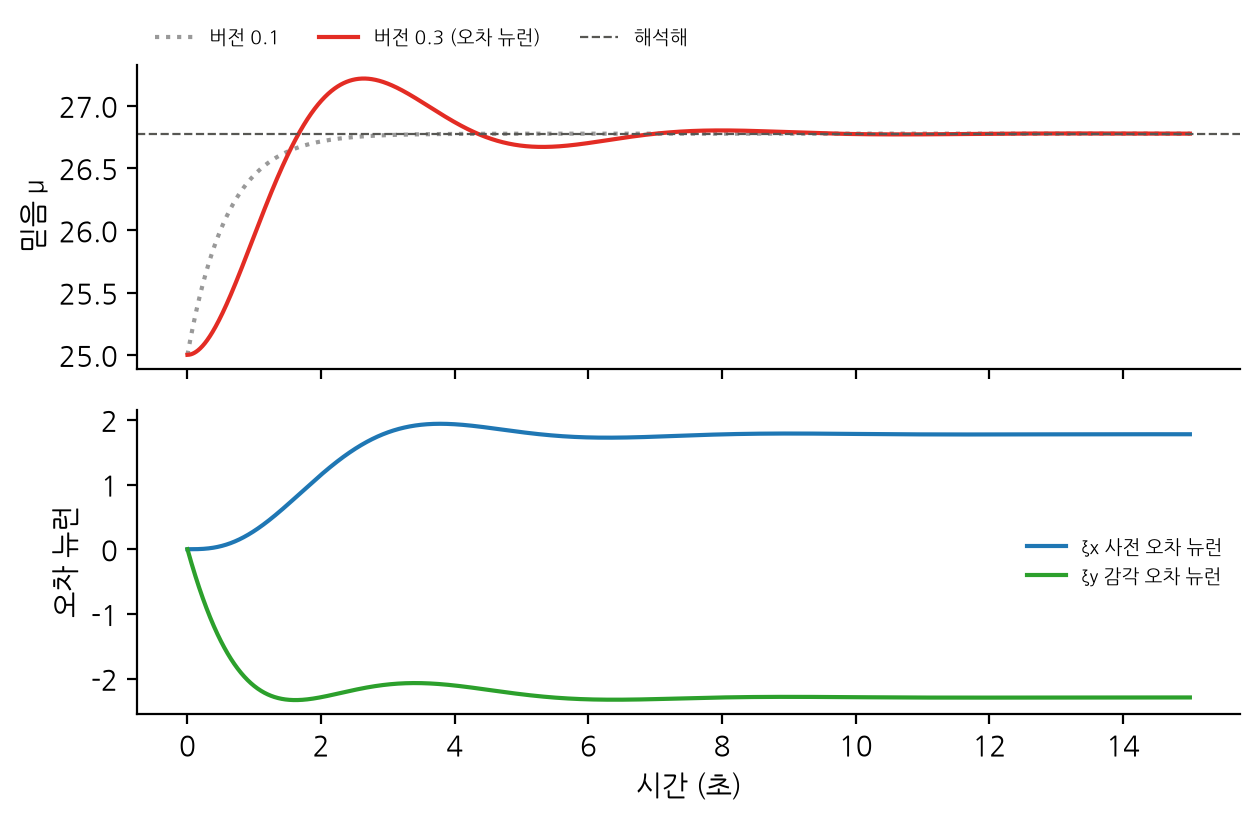

In [4]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.2))
ax[0].plot(t, r1["mu"], color="#999999", ls=":", label="버전 0.1")
ax[0].plot(t, r3["mu"], color="#E32C24", label="버전 0.3 (오차 뉴런)")
ax[0].axhline(mu_star, color="#575753", lw=0.8, ls="--", label="해석해")
ax[0].set_ylabel("믿음 μ")
ax[0].legend(frameon=False, fontsize=7, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
ax[1].plot(t, r3["xi"][:, 0], color="#1f77b4", label="ξx 사전 오차 뉴런")
ax[1].plot(t, r3["xi"][:, 1], color="#2ca02c", label="ξy 감각 오차 뉴런")
ax[1].set_ylabel("오차 뉴런")
ax[1].set_xlabel("시간 (초)")
ax[1].legend(frameon=False, fontsize=7, loc="center right")
fig.tight_layout()
plt.show()

## 3. 왜 진동하는가 — 선형화와 고윳값

상태를 s = (μ, ξx, ξy) 로 두고 정상점 근처에서 야코비 행렬 J = ∂ṡ/∂s 를 수치로 구한다. 고윳값의 실수부가 음수면 정상점으로 수렴하고, 허수부가 있으면 진동한다. 수렴 속도는 실수부가 가장 0 에 가까운 고윳값이 정한다. 버전 0.1 은 1 차원이므로 고윳값이 −α κ 하나다(κ 는 자유 에너지의 곡률).

In [5]:
def rhs_v03(s, mu_v, y, s_w, s_z, a, a_e):
    mu, xx, xy = s
    return np.array([-a * (xx - dg_gp(mu) * xy),
                     a_e * (mu - mu_v - s_w * xx),
                     a_e * (y - g_gp(mu) - s_z * xy)])

def fixed_point(s_w, s_z, mu_v=25.0, y=g_gp(30)):
    m = brentq(lambda m: (m - mu_v) / s_w - dg_gp(m) * (y - g_gp(m)) / s_z, 15, 40)
    return np.array([m, (m - mu_v) / s_w, (y - g_gp(m)) / s_z])

def jacobian(s_w, s_z, a=1.0, a_e=1.0, h=1e-6):
    s0 = fixed_point(s_w, s_z)
    J = np.zeros((3, 3))
    for k in range(3):
        d = np.zeros(3); d[k] = h
        J[:, k] = (rhs_v03(s0 + d, 25.0, g_gp(30), s_w, s_z, a, a_e)
                   - rhs_v03(s0 - d, 25.0, g_gp(30), s_w, s_z, a, a_e)) / (2 * h)
    return J

def kappa(s_w, s_z):
    m = fixed_point(s_w, s_z)[0]
    h = 1e-5
    dF = lambda m: (m - 25) / s_w - dg_gp(m) * (g_gp(30) - g_gp(m)) / s_z
    return (dF(m + h) - dF(m - h)) / (2 * h)

lam = np.linalg.eigvals(jacobian(1.0, 1.0))
print("버전 0.3 의 고윳값:", "  ".join(f"{l.real:+.3f}{l.imag:+.3f}j" for l in sorted(lam, key=lambda l: l.real)))
print(f"버전 0.1 의 고윳값: {-kappa(1.0, 1.0):+.3f}")
osc = [l for l in lam if abs(l.imag) > 1e-9]
if osc:
    print(f"진동 주기 2π/|Im λ| = {2 * np.pi / abs(osc[0].imag):.2f}s,  감쇠 시간 1/|Re λ| = {1 / abs(osc[0].real):.2f}s")

버전 0.3 의 고윳값: -1.000+0.000j  -0.531+1.175j  -0.531-1.175j
버전 0.1 의 고윳값: -1.664
진동 주기 2π/|Im λ| = 5.35s,  감쇠 시간 1/|Re λ| = 1.88s


## 4. 정밀도를 높여도 빨라지지 않는다

두 분산을 함께 10, 1, 0.1 로 바꾼다. 버전 0.1 은 정밀도가 높을수록 빨라졌다(6.7). 버전 0.3 은?

In [6]:
print("두 분산   버전 0.1 수렴(고윳값)      버전 0.3 수렴   0.3 최대 넘침   0.3 의 가장 느린 고윳값")
fmt = lambda s: "15초 안 못함" if np.isinf(s) else f"{s:.2f}s"
for s2 in [10.0, 1.0, 0.1]:
    m_star = fixed_point(s2, s2)[0]
    r_1 = simulation(30.0, 25.0, s2, s2, version=1)
    r_3 = simulation(30.0, 25.0, s2, s2, version=3)
    lam = np.linalg.eigvals(jacobian(s2, s2))
    slow = max(lam, key=lambda l: l.real)
    print(f"{s2:6.1f}    {fmt(settle_time(r_1['mu'], m_star)):>12s} ({-kappa(s2, s2):+.3f})   {fmt(settle_time(r_3['mu'], m_star)):>12s}"
          f"     {r_3['mu'].max() - m_star:+8.3f}      {slow.real:+.3f}{slow.imag:+.3f}j")

두 분산   버전 0.1 수렴(고윳값)      버전 0.3 수렴   0.3 최대 넘침   0.3 의 가장 느린 고윳값


  10.0        15초 안 못함 (-0.166)       15초 안 못함       -0.142      -0.169+0.000j


   1.0           2.75s (-1.664)          8.70s       +0.442      -0.531+1.175j


   0.1           0.27s (-16.635)       15초 안 못함       +1.410      -0.100+0.000j


## 5. 오차 뉴런을 빠르게 — 시간 척도 분리

보가츠의 유도는 오차 뉴런이 믿음보다 빨리 수렴한다고 가정한다. 오차 뉴런의 속도 αε 를 믿음의 α 보다 10 배, 100 배 크게 둔다.

In [7]:
print("αε/α    1% 수렴    최대 넘침     가장 느린 고윳값")
for ratio in [1, 10, 100]:
    r = simulation(30.0, 25.0, version=3, a_eps=ratio * 1.0)
    lam = np.linalg.eigvals(jacobian(1.0, 1.0, 1.0, ratio * 1.0))
    slow = max(lam, key=lambda l: l.real)
    print(f"{ratio:4d}   {settle_time(r['mu'], mu_star):7.2f}s   {r['mu'].max() - mu_star:+9.4f}     {slow.real:+.3f}{slow.imag:+.3f}j")
print(f"버전 0.1: {settle_time(r1['mu'], mu_star):7.2f}s   고윳값 {-kappa(1.0, 1.0):+.3f}")

αε/α    1% 수렴    최대 넘침     가장 느린 고윳값


   1      8.70s     +0.4425     -0.531+1.175j


  10      2.36s     -0.0000     -2.085+0.000j


 100      2.73s     -0.0000     -1.691+0.000j
버전 0.1:    2.75s   고윳값 -1.664


## 6. 잡음 속에서, 학습률을 바꾸면

백색 잡음(분산 0.1)과 유색 잡음(분산 1, 매끄러움 1/2000)에서 두 버전의 마지막 5 초 평균을 비교하고, 학습률 1, 2, 4, 10 에서 수렴 시간을 잰다.

In [8]:
tail = t > 10
for name, kw in [("백색 0.1", dict(s_w=0.1, s_z=0.1, noise="white")), ("유색 1", dict(noise="smooth"))]:
    m1 = simulation(30.0, 25.0, version=1, **kw)["mu"][tail]
    m3 = simulation(30.0, 25.0, version=3, **kw)["mu"][tail]
    print(f"{name:7s}  버전 0.1 평균 {m1.mean():.3f} (표준편차 {m1.std():.3f})   버전 0.3 평균 {m3.mean():.3f} (표준편차 {m3.std():.3f})")
print()
print("학습률   버전 0.1 수렴   버전 0.3 수렴")
for a in [1, 2, 4, 10]:
    s1 = settle_time(simulation(30.0, 25.0, a_mu=a, version=1)["mu"], mu_star)
    s3 = settle_time(simulation(30.0, 25.0, a_mu=a, version=3)["mu"], mu_star)
    print(f"{a:5d}    {s1:9.2f}s     {s3:9.2f}s")

백색 0.1   버전 0.1 평균 26.781 (표준편차 0.035)   버전 0.3 평균 26.777 (표준편차 0.142)


유색 1     버전 0.1 평균 26.803 (표준편차 0.160)   버전 0.3 평균 26.818 (표준편차 0.113)

학습률   버전 0.1 수렴   버전 0.3 수렴


    1         2.75s          8.70s


    2         1.37s          4.34s


    4         0.68s          2.17s


   10         0.27s          0.85s


## 7. 실패 조건 — 이산 시간의 한계

전진 오일러는 고윳값 λ 마다 한 걸음에 (1 + Δt·λ) 배가 된다. 모든 고윳값에서 |1 + Δt·λ| < 1 이어야 수렴한다. 학습률 α 를 키우면 고윳값이 α 에 비례해 커진다.

In [9]:
def step_map(s, a, s_w=1.0, s_z=1.0, mu_v=25.0, y=g_gp(30)):
    """capsule_v03.step 과 같은 순서의 한 걸음: 오차 뉴런을 먼저, 믿음은 새 오차로."""
    mu, xx, xy = s
    e_x, e_y = mu - mu_v, y - g_gp(mu)
    xx = xx + dt * a * (e_x - s_w * xx)
    xy = xy + dt * a * (e_y - s_z * xy)
    mu = mu + dt * -a * (xx - dg_gp(mu) * xy)
    return np.array([mu, xx, xy])

def spectral_radius(a, h=1e-7):
    s0 = fixed_point(1.0, 1.0)
    M = np.column_stack([(step_map(s0 + h * e, a) - step_map(s0 - h * e, a)) / (2 * h) for e in np.eye(3)])
    return np.abs(np.linalg.eigvals(M)).max()

lam1 = np.linalg.eigvals(jacobian(1.0, 1.0))
a_euler = min(a for a in np.arange(1, 2000, 1.0) if np.abs(1 + dt * a * lam1).max() >= 1)
a_map = min(a for a in np.arange(1, 2000, 1.0) if spectral_radius(a) >= 1)
print(f"순수 전진 오일러로 본 한계 ≈ {a_euler:.0f},  실제 갱신 순서로 본 한계 ≈ {a_map:.0f},  버전 0.1 의 한계 ≈ {2 / (dt * kappa(1.0, 1.0)):.0f}")
print()
print("학습률   한 걸음 사상의 스펙트럼 반지름    15초 μ")
with np.errstate(all="ignore"):
    for a in [100, a_map - 10, a_map + 10, 1000]:
        r = simulation(30.0, 25.0, a_mu=a, version=3)
        print(f"{a:6.0f}          {spectral_radius(a):6.3f}               {r['mu'][-1]:10.4g}")

순수 전진 오일러로 본 한계 ≈ 128,  실제 갱신 순서로 본 한계 ≈ 213,  버전 0.1 의 한계 ≈ 240

학습률   한 걸음 사상의 스펙트럼 반지름    15초 μ


   100           0.696                    26.78


   203           0.747                    26.78


   223           1.260                    20.89


  1000          43.402                      nan


## 결론

- 오차 뉴런을 둔 버전 0.3 은 버전 0.1 과 같은 믿음에 수렴하고, 오차 뉴런의 값은 정밀도 가중 예측 오차가 된다.
- 다만 길이 다르다. 상태가 셋인 선형 계의 고윳값이 복소수라 감쇠 진동하며 간다.
- 정밀도를 높이면 버전 0.1 은 빨라지지만 버전 0.3 은 오차 뉴런의 누설이 느려져 진동이 커진다.
- 오차 뉴런을 믿음보다 충분히 빠르게 하면 진동이 사라지고 버전 0.1 의 거동으로 돌아간다. 보가츠 유도의 숨은 가정이 시간 척도 분리다.
- 학습률은 모든 고윳값이 이산 시간의 안정 영역 안에 있도록 골라야 한다.